## Projeto de Aprendizagem Estatística

In [12]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import binned_statistic_2d, gaussian_kde


sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette=["#315C8C", "#24A19C", "#F4A261", "#D95D78", "#7B6DCC"],
)
plt.rcParams.update({
    "figure.dpi": 130,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelcolor": "#344054",
    "text.color": "#243447",
    "grid.color": "#DCE3EA",
    "grid.alpha": 0.65,
})

from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error

def avaliar_rmse_cv(X, y, ajustar_prever, k=8, random_state=42):
    """
    Avalia um modelo por validação cruzada e devolve o RMSE de cada fold.

    ajustar_prever(X_treino, y_treino, X_validacao) deve ajustar o modelo
    somente com o treino e retornar as previsões para a validação.
    """
    dados_cv = X.join(y.rename("_alvo")).dropna()
    X_cv = dados_cv.drop(columns="_alvo")
    y_cv = dados_cv["_alvo"].astype(float)

    cv = KFold(n_splits=k, shuffle=True, random_state=random_state)
    erros = []

    for idx_treino, idx_validacao in cv.split(X_cv):
        X_treino = X_cv.iloc[idx_treino]
        X_validacao = X_cv.iloc[idx_validacao]
        y_treino = y_cv.iloc[idx_treino]
        y_validacao = y_cv.iloc[idx_validacao]

        previsoes = ajustar_prever(X_treino, y_treino, X_validacao)
        previsoes = np.clip(np.asarray(previsoes, dtype=float), 0, 5)
        erros.append(mean_squared_error(y_validacao, previsoes) ** 0.5)

    return np.asarray(erros)


In [3]:
df = pd.read_csv("train.csv")
df["stars"] = pd.Categorical(
    df["stars"],
    categories=sorted(df["stars"].dropna().unique()),
    ordered=True,
)
df.head()

,pair_id,user_avg_stars,user_n_ratings,age,share_action,share_comedy,share_drama,movie_avg_stars,movie_n_ratings,genre,release_year,stars
0,P00001,2.99,15,48,0.315,0.501,0.184,3.61,71,drama,2012,3
1,P00002,3.44,35,57,0.180,0.151,0.669,3.15,35,action,2015,2
2,P00003,3.91,46,27,0.701,0.258,0.041,2.72,36,action,1982,4
3,P00004,4.23,23,18,0.700,0.204,0.096,3.26,29,action,2021,5
4,P00005,3.54,29,16,0.621,0.257,0.122,2.83,11,action,2002,4


### Descrição dos Dados

O arquivo `train.csv` contém 4.000 observações. Os exemplos abaixo correspondem à primeira linha do arquivo. Cada linha representa uma combinação entre usuário e filme; a variável resposta é a nota atribuída, de 0 a 5 estrelas. Os dados são fictícios e simulam avaliações de uma plataforma de filmes.

#### Identificação e resposta

| Variável | O que representa | Exemplo |
|---|---|---|
| `pair_id` | Identificador único da combinação usuário–filme. Serve para identificar a linha, não como preditor. | `P00001` |
| `stars` | Nota dada pelo usuário ao filme; variável que queremos explicar ou prever. | `3` estrelas |

#### Características do usuário

| Variável | O que representa | Exemplo |
|---|---|---|
| `user_avg_stars` | Média das notas que o usuário deu a outros filmes. | `2,99` estrelas |
| `user_n_ratings` | Quantidade de avaliações anteriores do usuário. | `15` avaliações |
| `age` | Idade do usuário, em anos. | `48` anos |
| `share_action` | Proporção de filmes de ação no histórico do usuário. | `0,315` = 31,5% |
| `share_comedy` | Proporção de comédias no histórico do usuário. | `0,501` = 50,1% |
| `share_drama` | Proporção de dramas no histórico do usuário. | `0,184` = 18,4% |

As três proporções de gênero somam 1. Por isso, ao usar intercepto em uma regressão, incluímos apenas duas delas para evitar colinearidade perfeita.

#### Características do filme

| Variável | O que representa | Exemplo |
|---|---|---|
| `movie_avg_stars` | Média das notas recebidas anteriormente pelo filme. | `3,61` estrelas |
| `movie_n_ratings` | Quantidade de avaliações anteriores do filme. | `71` avaliações |
| `genre` | Gênero do filme: ação, comédia ou drama. | `drama` |
| `release_year` | Ano de lançamento do filme. | `2012` |

As médias e contagens anteriores são preditores importantes. Para evitar vazamento de informação, elas devem ter sido calculadas sem incluir a nota que o modelo está tentando prever.


In [4]:
num = df.select_dtypes(include="number").columns
cat = df.select_dtypes(include=["object", "category", "string"]).columns
cat = cat[~cat.isin(["pair_id", "stars"]) ]
df[num].describe().T

,count,mean,std,min,25%,50%,75%,max
user_avg_stars,4000.0,3.337270,0.709814,1.040,2.84000,3.340,3.800,5.000
user_n_ratings,4000.0,58.524250,86.286852,3.000,14.00000,27.000,60.000,1016.000
age,4000.0,36.529250,14.000255,16.000,24.00000,36.000,47.000,79.000
share_action,4000.0,0.389709,0.190547,0.043,0.23700,0.367,0.533,0.867
share_comedy,4000.0,0.295158,0.115637,0.058,0.20775,0.280,0.370,0.722
share_drama,4000.0,0.315133,0.208623,0.031,0.13400,0.238,0.510,0.838
movie_avg_stars,4000.0,3.012265,0.755076,0.310,2.51000,3.010,3.530,5.000
movie_n_ratings,4000.0,55.054750,69.894771,5.000,17.00000,34.000,66.000,1345.000
release_year,4000.0,2004.125500,15.019975,1970.000,1993.00000,2007.500,2017.000,2024.000


### Histogramas das Variáveis Numéricas

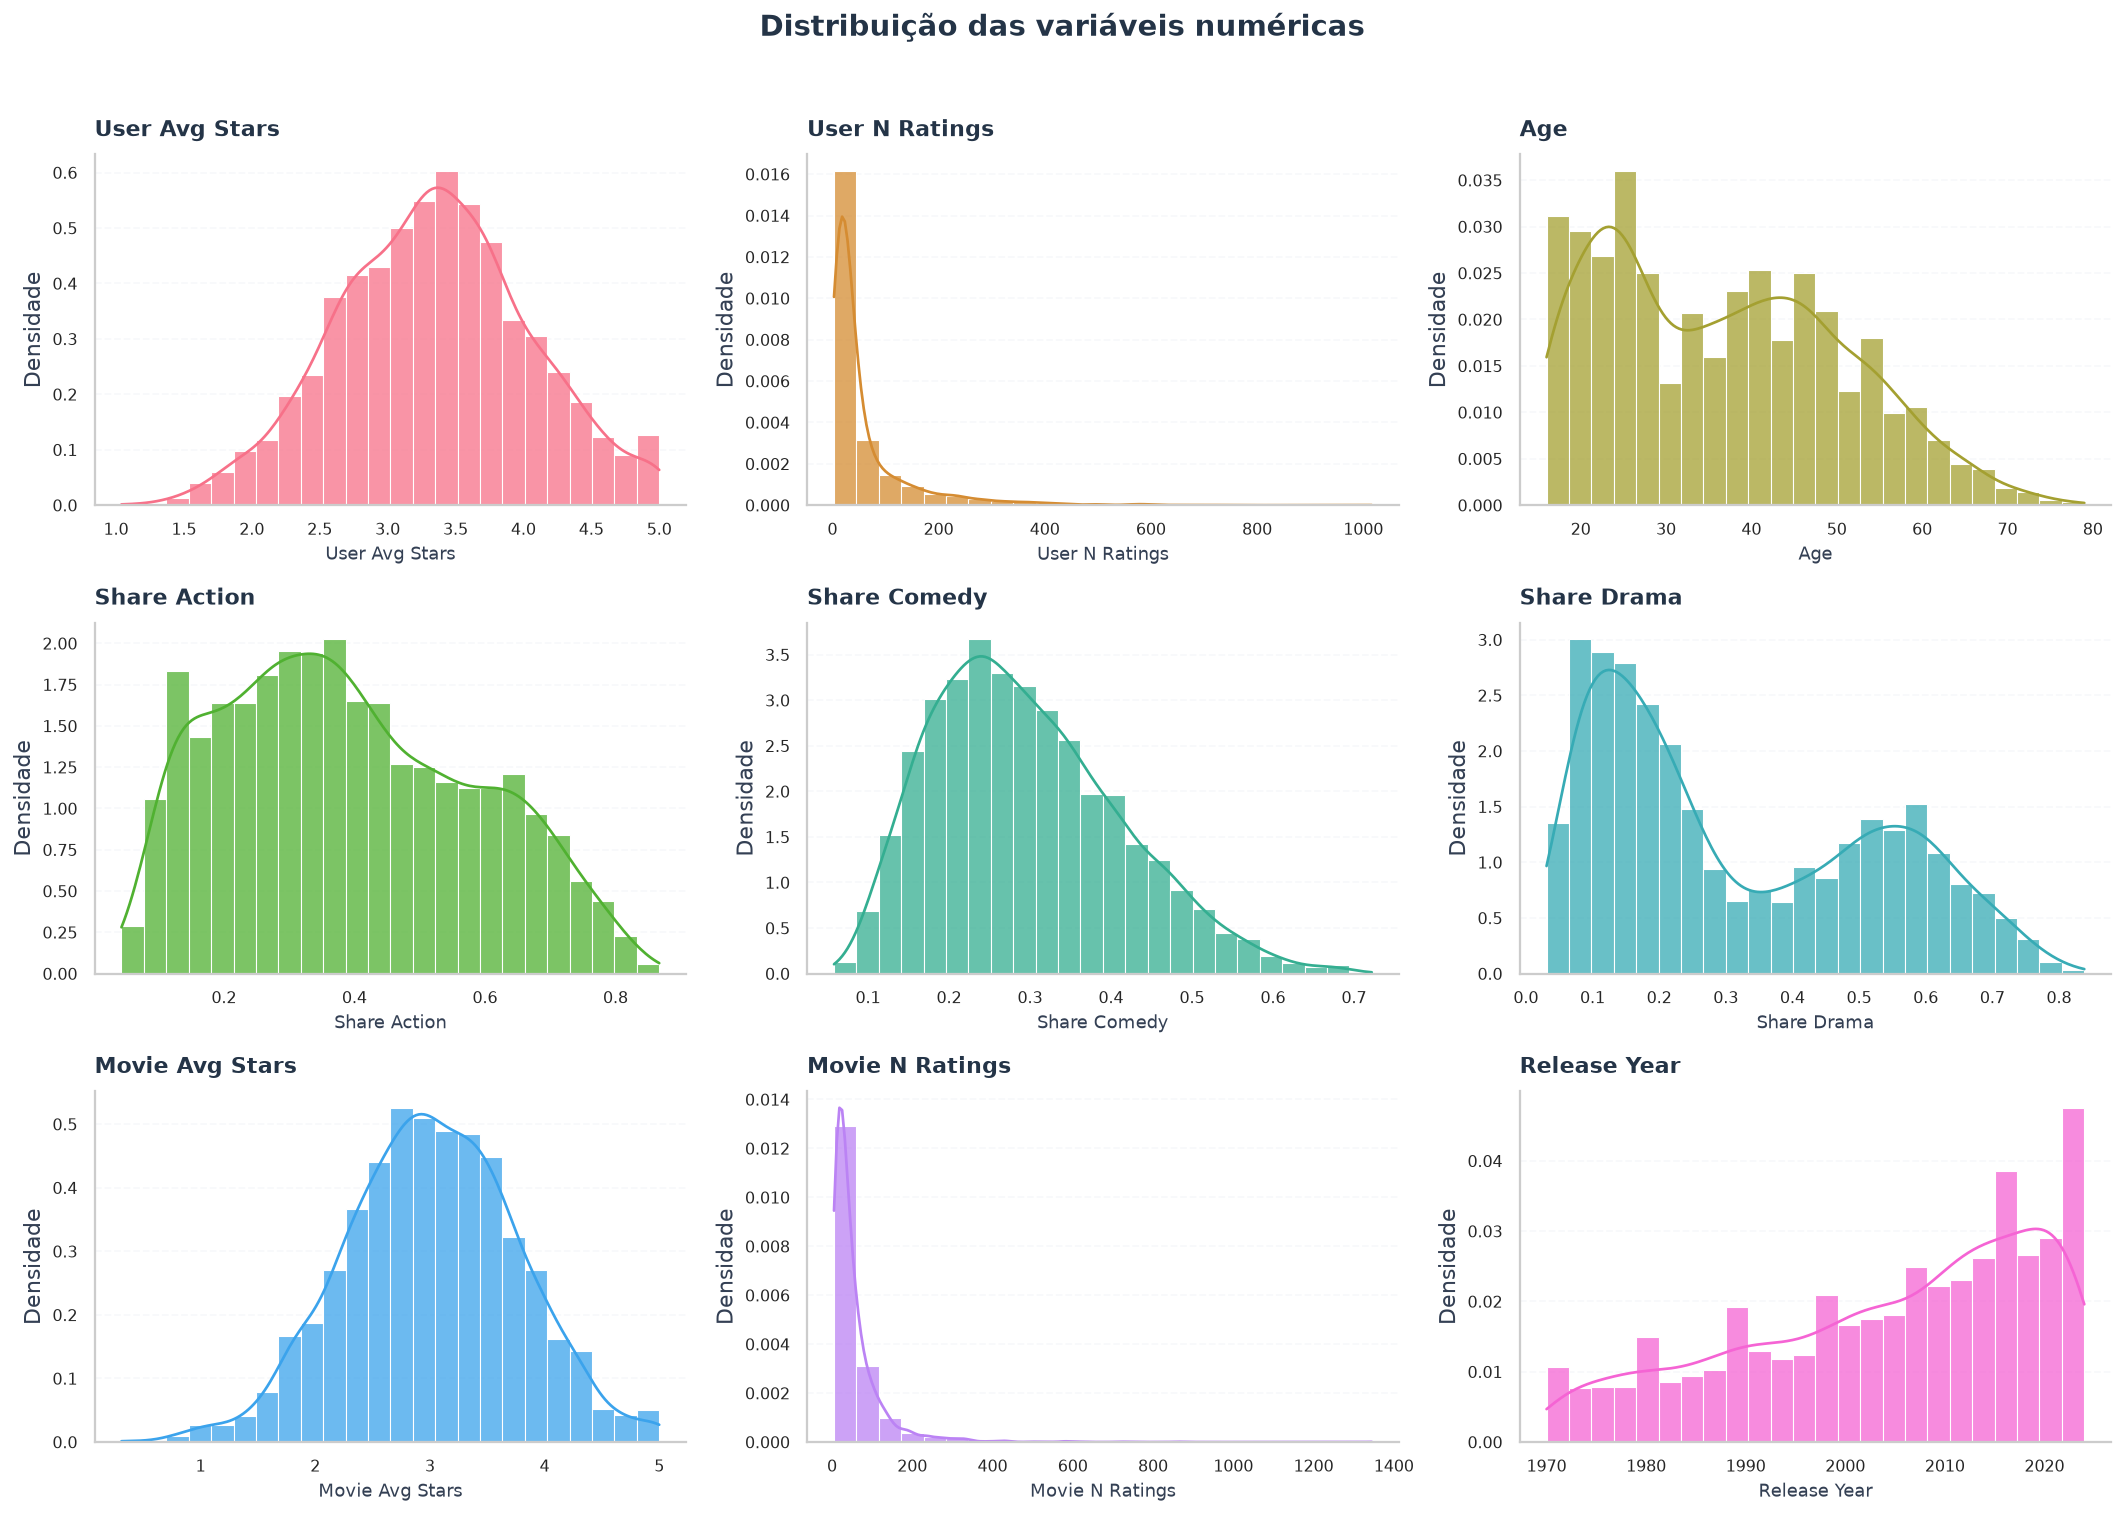

In [5]:
def painel(cols, plot_func, ncols=3, titulo="Distribuição das variáveis numéricas", **kwargs):

    nrows = math.ceil(len(cols) / ncols)
    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(5.5 * ncols, 3.8 * nrows),
        squeeze=False
    )

    axes = axes.ravel()
    palette = sns.color_palette("husl", len(cols))

    for i, (ax, col) in enumerate(zip(axes, cols)):

        plot_func(
            data=df,
            x=col,
            ax=ax,
            color=palette[i],
            edgecolor="white",
            linewidth=0.6,
            **kwargs
        )

        nome = col.replace("_", " ").title()

        ax.set_title(nome, loc="left", fontsize=12, fontweight="bold", pad=10)
        ax.set_xlabel(nome, fontsize=10)
        ax.set_ylabel("Densidade" if kwargs.get("stat") == "density" else "Frequência")

        ax.grid(axis="y", alpha=0.2, linestyle="--")
        ax.grid(axis="x", visible=False)

        ax.tick_params(axis="both", labelsize=9)
        sns.despine(ax=ax)

    for ax in axes[len(cols):]:
        ax.set_visible(False)

    fig.suptitle(
        titulo,
        fontsize=16,
        fontweight="bold",
        y=1.02
    )

    fig.tight_layout()
    plt.show()
    
painel(
    num,
    sns.histplot,
    kde=True,
    stat="density",
    bins=24,
    alpha=0.75
)

### Distribuição das Variáveis Categóricas e Ordinais

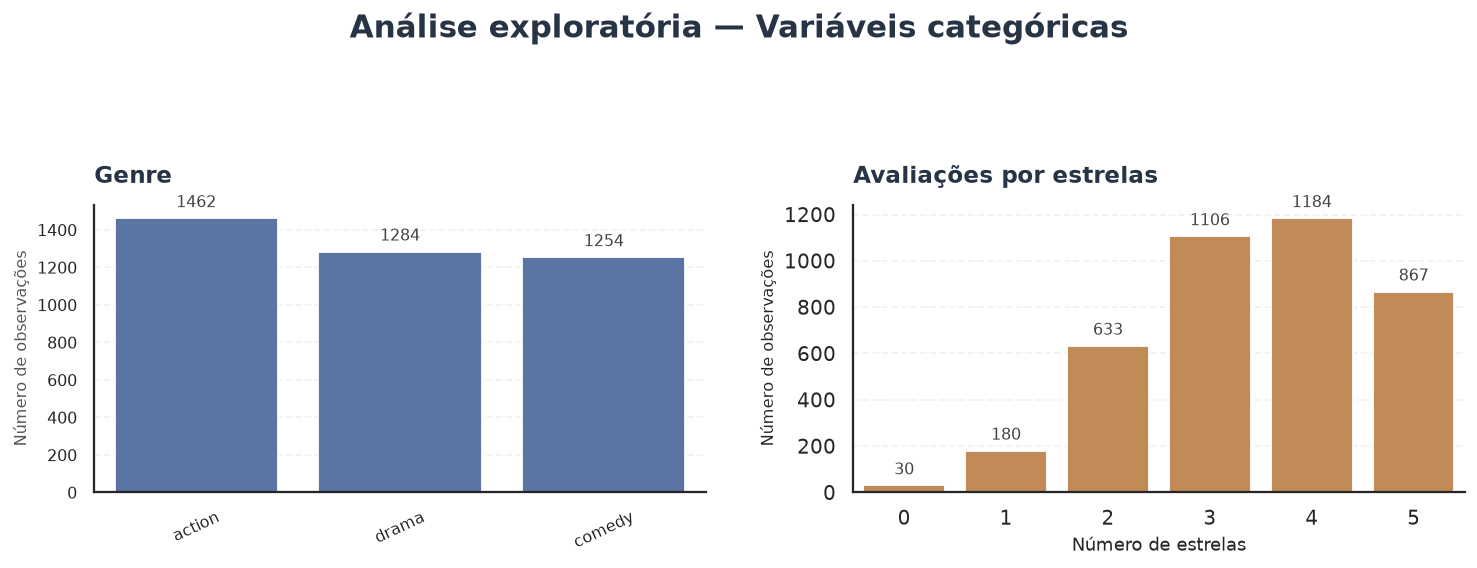

In [6]:
# Configuração visual
sns.set_theme(style="white", context="notebook")

n = len(cat) + 1
ncols = min(n, 3)
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(6 * ncols, 4.5 * nrows),
    squeeze=False
)

axes = axes.flatten()

# Paleta
colors = sns.color_palette("deep", n_colors=n)

# Variáveis categóricas
for i, col in enumerate(cat):

    ax = axes[i]
    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        x=col,
        order=order,
        color=colors[i],
        edgecolor="white",
        linewidth=1,
        ax=ax
    )

    # Valores nas barras
    for container in ax.containers:
        ax.bar_label(container, padding=4, fontsize=9, color="#444444")

    ax.set_title(
        col.replace("_", " ").title(),
        loc="left",
        fontsize=13,
        fontweight="bold",
        color="#263445",
        pad=12
    )

    ax.set_xlabel("")
    ax.set_ylabel("Número de observações", fontsize=9, color="#555555")
    ax.tick_params(axis="x", rotation=25, labelsize=9)
    ax.tick_params(axis="y", labelsize=9)

    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)

    sns.despine(ax=ax, left=False, bottom=False)


# Avaliações
ax = axes[len(cat)]

sns.countplot(
    data=df,
    x="stars",
    order=sorted(df["stars"].dropna().unique()),
    color="#D28B45",
    edgecolor="white",
    linewidth=1,
    ax=ax
)

for container in ax.containers:
    ax.bar_label(container, padding=4, fontsize=9, color="#444444")

ax.set_title(
    "Avaliações por estrelas",
    loc="left",
    fontsize=13,
    fontweight="bold",
    color="#263445",
    pad=12
)

ax.set_xlabel("Número de estrelas", fontsize=10)
ax.set_ylabel("Número de observações", fontsize=9)

ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

sns.despine(ax=ax)


# Ocultar espaços vazios
for ax in axes[n:]:
    ax.set_visible(False)

fig.suptitle(
    "Análise exploratória — Variáveis categóricas",
    fontsize=17,
    fontweight="bold",
    color="#263445",
    y=1.02
)

fig.tight_layout(pad=2.5)
plt.show()

### Análise de Correlação das Covariáveis (Correlograma)

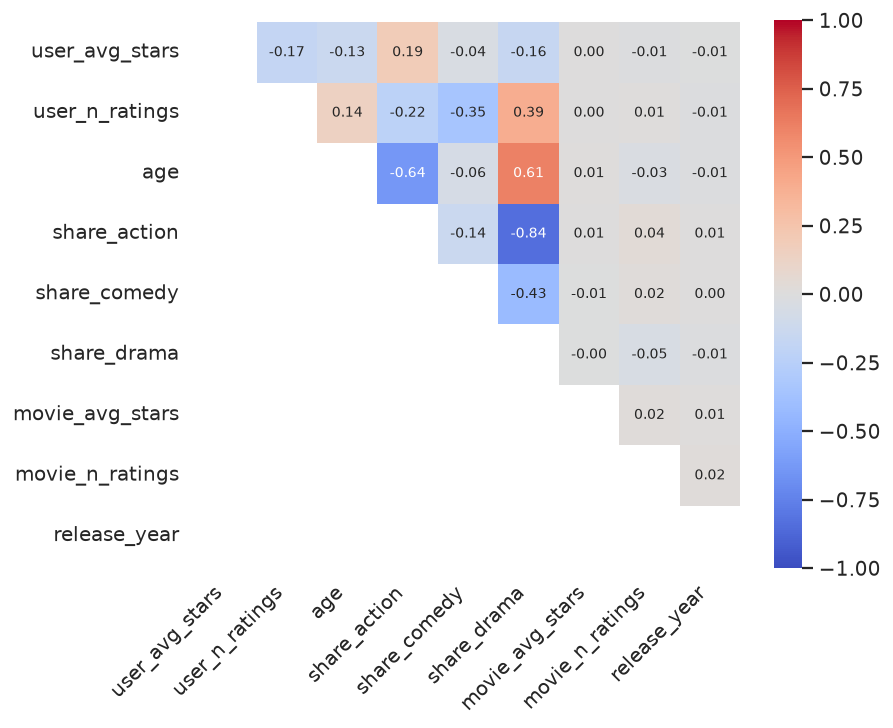

In [7]:
corr = df.select_dtypes(include="number").corr()
mascara = np.tril(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(7, 7))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", annot_kws={"size": 8},
            cmap="coolwarm", vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.7}, ax=ax)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Análise de Multicolinearidade

In [8]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif1 = df_num.copy()
vif_df = pd.DataFrame({
    "Variável": X_vif1.columns[1:],
    "VIF": [
        variance_inflation_factor(X_vif1.to_numpy(), i)
        for i in range(1, X_vif1.shape[1])
    ],
})
vif_df.sort_values("VIF", ascending=False)


,Variável,VIF
4,share_drama,172335.465699
2,share_action,143738.780527
3,share_comedy,52936.019430
1,age,1.758481
0,user_n_ratings,1.280027
6,movie_n_ratings,1.004460
5,movie_avg_stars,1.001688
7,release_year,1.001228


**Comentários**
As variáveis share_drama, share_action e share_comedy são muito correlatas e acabam inflando a lineariedade dos nossos dados, interferindo na separação. Desse modo uma exclusão dentre eles se faz necessária. 

In [ ]:
from statsmodels.api import add_constant
# Sem perda de generalidade, vamos remover a variável "share_comedy" do cálculo do VIF
X_vif2 = add_constant(df_num.drop(columns=["share_comedy"], errors="ignore"))
vif_df2 = pd.DataFrame({
    "Variável": X_vif2.columns[1:],
    "VIF": [
        variance_inflation_factor(X_vif2.to_numpy(), i)
        for i in range(1, X_vif2.shape[1])
    ],
})
vif_df2.sort_values("VIF", ascending=False)


,Variável,VIF
4,share_drama,4.124366
3,share_action,3.805929
2,age,1.757760
1,user_n_ratings,1.279985
0,user_avg_stars,1.065324
6,movie_n_ratings,1.003757
5,movie_avg_stars,1.001027
7,release_year,1.000655


### Análise de interação entre o gênero e o histórico

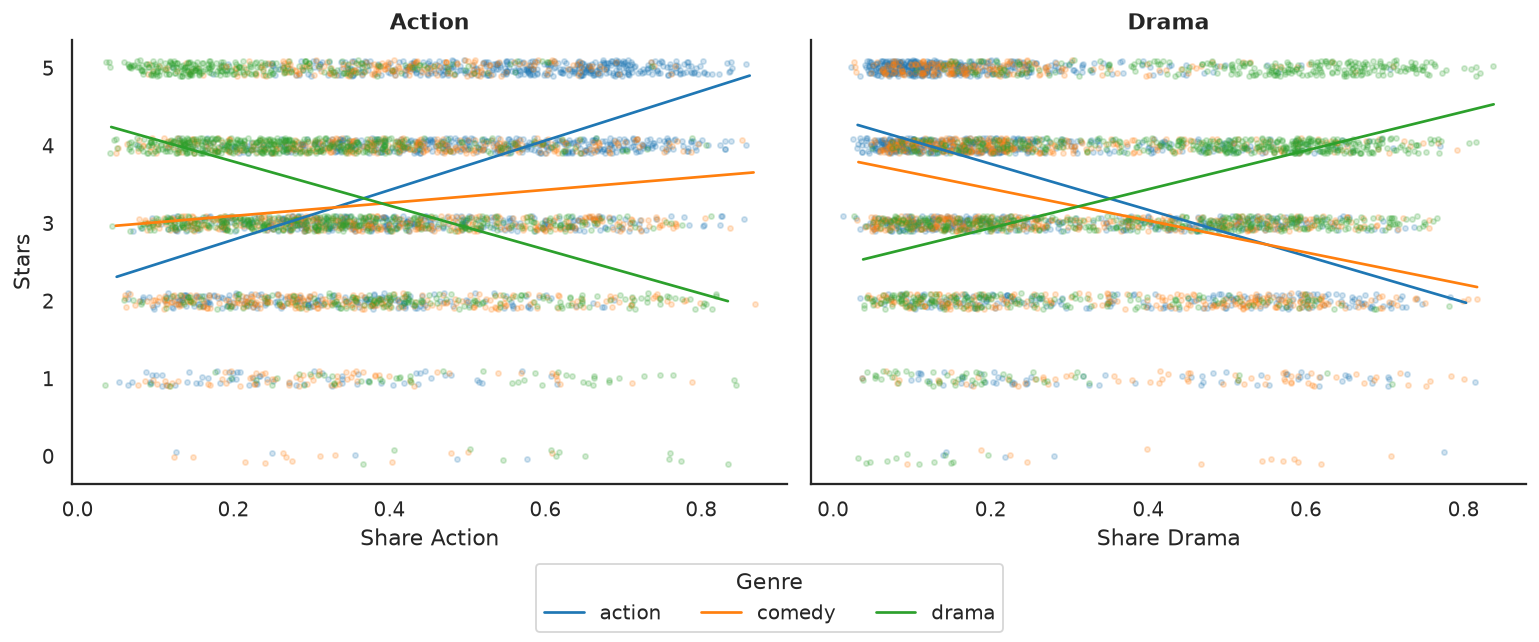

In [10]:
dados = df.drop(columns="share_comedy").copy()

# Garantir que as variáveis sejam numéricas
colunas = ["stars", "share_action", "share_drama"]

for col in colunas:
    dados[col] = pd.to_numeric(dados[col], errors="coerce")

generos = sorted(dados["genre"].dropna().unique())
cores = dict(zip(generos, sns.color_palette("tab10", len(generos))))

rng = np.random.default_rng(42)


def dispersao_por_genero(ax, x, largura, altura):

    for genero in generos:

        sub = dados.loc[
            dados["genre"] == genero,
            [x, "stars"]
        ].dropna()

        # Jitter nos pontos
        x_jitter = sub[x] + rng.uniform(-largura, largura, len(sub))
        y_jitter = sub["stars"] + rng.uniform(-altura, altura, len(sub))

        ax.scatter(
            x_jitter,
            y_jitter,
            alpha=0.2,
            s=8,
            color=cores[genero]
        )

        # Reta de regressão
        if len(sub) >= 2 and sub[x].nunique() > 1:

            coef = np.polyfit(sub[x], sub["stars"], 1)

            xs = np.linspace(sub[x].min(), sub[x].max(), 100)

            ax.plot(
                xs,
                np.polyval(coef, xs),
                color=cores[genero],
                linewidth=1.5,
                label=genero
            )


fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(12, 5),
    sharey=True
)

dispersao_por_genero(ax1, "share_action", 0.02, 0.1)
ax1.set_xlabel("Share Action")
ax1.set_ylabel("Stars")
ax1.set_title("Action")

dispersao_por_genero(ax2, "share_drama", 0.02, 0.1)
ax2.set_xlabel("Share Drama")
ax2.set_title("Drama")

handles, rotulos = ax1.get_legend_handles_labels()

fig.legend(
    handles,
    rotulos,
    loc="lower center",
    ncol=len(generos),
    title="Genre"
)

sns.despine()

plt.tight_layout(rect=(0, 0.10, 1, 1))
plt.show()

### Análise da distribuição de estrelas por gênero (Violin Plot com Suavização)

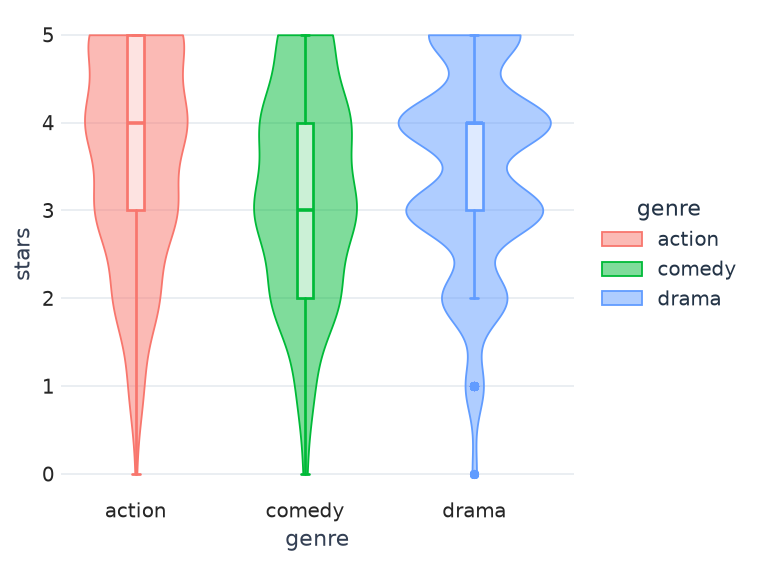

In [15]:
from matplotlib.colors import to_rgba
from matplotlib.patches import Patch

ordem = sorted(dados["genre"].unique())
paleta = dict(zip(ordem, ["#F8766D", "#00BA38", "#619CFF"]))
grupos = [dados.loc[dados["genre"] == g, "stars"].to_numpy() for g in ordem]

def largura_nrd0(x):
    sd = np.std(x, ddof=1)
    iqr = np.subtract(*np.percentile(x, [75, 25]))
    h = min(sd, iqr / 1.34) if iqr > 0 else sd
    return 0.9 * h * len(x) ** (-0.2)

# FATOR DE SUAVIZAÇÃO: Aumente este valor para deixar mais suave (ex: 1.5, 2.0)
fator_suavizacao = 1.8

curvas = []
for x in grupos:
    # Multiplicamos o resultado da largura de banda pelo fator para suavizar a curva
    largura_ajustada = (largura_nrd0(x) / np.std(x, ddof=1)) * fator_suavizacao
    kde = gaussian_kde(x, bw_method=largura_ajustada)
    grade = np.linspace(x.min(), x.max(), 512)
    curvas.append((grade, kde(grade)))
dens_max = max(d.max() for _, d in curvas)

fig, ax = plt.subplots(figsize=(6, 4.5))
for i, (g, (grade, dens)) in enumerate(zip(ordem, curvas)):
    meia_largura = dens / dens_max * 0.45
    ax.fill_betweenx(grade, i - meia_largura, i + meia_largura,
                     facecolor=to_rgba(paleta[g], 0.5), edgecolor=paleta[g], linewidth=1)

caixas = ax.boxplot(grupos, positions=range(len(ordem)), widths=0.1, patch_artist=True,
                    manage_ticks=False)
for i, g in enumerate(ordem):
    cor = paleta[g]
    caixas["boxes"][i].set(facecolor=to_rgba("white", 0.6), edgecolor=cor, linewidth=1.5)
    caixas["medians"][i].set(color=cor, linewidth=2)
    for parte in ("whiskers", "caps"):
        for linha in caixas[parte][2 * i:2 * i + 2]:
            linha.set(color=cor, linewidth=1.5)
    caixas["fliers"][i].set(marker="o", markersize=4, markerfacecolor=cor, markeredgecolor=cor)

ax.set_xticks(range(len(ordem)))
ax.set_xticklabels(ordem)
ax.set_yticks(range(0, 6))
ax.set_xlabel("genre")
ax.set_ylabel("stars")
ax.grid(axis="x", visible=False)
ax.tick_params(length=0)
sns.despine(left=True, bottom=True)
ax.legend(handles=[Patch(facecolor=to_rgba(paleta[g], 0.5), edgecolor=paleta[g], label=g) for g in ordem],
          title="genre", loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
plt.tight_layout()
plt.show()

### Criando as Variáveis e Controlando a Multicolineariedade

In [ ]:
from sklearn.linear_model import LinearRegression

X_res = df[["user_avg_stars", "movie_avg_stars"]]
resid = df["stars"] - LinearRegression().fit(X_res, df["stars"]).predict(X_res)

plt.figure(figsize=(6, 4))
plt.scatter(df["share_match"], resid, alpha=0.2, s=8)
b = pd.qcut(df["share_match"], 15, duplicates="drop")
m = pd.DataFrame({"x": df["share_match"], "r": resid}).groupby(b, observed=True).mean()
plt.plot(m["x"], m["r"], "r-o")
plt.axhline(0, color="k", lw=0.8)
plt.xlabel("share_match"); plt.ylabel("residual")
plt.show()

In [ ]:
# Criando variável de afinidade do usuário com o gênero do filme

# Como ela funciona: 

# se o gênero do filme for "action", a afinidade será igual à share_action; 
# se for "comedy", será igual à share_comedy; 
# caso contrário, será igual à share_drama.

# Dessa forma, não precisamos carregar as 3 variáveis share_comedy, share_drama e share_action, que são 
# altamente correlacionadas entre si.
dados = df.copy()
dados["stars"] = pd.to_numeric(dados["stars"], errors="coerce")
dados = dados.dropna(subset=["stars"]).copy()
dados["log_user_n_ratings"] = np.log1p(dados["user_n_ratings"])
dados["log_movie_n_ratings"] = np.log1p(dados["movie_n_ratings"])
dados["age_x_year"] = dados["age"] * dados["release_year"]
dados["age_at_release"] = dados["release_year"] - (2026 - dados["age"])
dados["share_match"] = np.select(
    [dados["genre"].eq("action"), dados["genre"].eq("comedy")],
    [dados["share_action"], dados["share_comedy"]],
    default=dados["share_drama"],
)

#### Analisando as variáveis finais

In [13]:
X_vif3 = dados.select_dtypes(include="number").copy()
X_vif3 = add_constant(X_vif3.drop(columns=["share_comedy"], errors="ignore"))
X_vif3 = add_constant(X_vif3.drop(columns=["share_action"], errors="ignore"))
X_vif3 = add_constant(X_vif3.drop(columns=["share_drama"], errors="ignore"))
X_vif3 = add_constant(X_vif3.drop(columns=["user_n_ratings"], errors="ignore"))
X_vif3 = add_constant(X_vif3.drop(columns=["movie_n_ratings"], errors="ignore"))
X_vif3 = add_constant(X_vif3.drop(columns=["stars"], errors="ignore"))
X_vif3 = add_constant(X_vif3.drop(columns=["age"], errors="ignore"))
X_vif3 = add_constant(X_vif3.drop(columns=["release_year"], errors="ignore"))

vif_df3 = pd.DataFrame({
    "Variável": X_vif3.columns[1:],
    "VIF": [
        variance_inflation_factor(X_vif3.to_numpy(), i)
        for i in range(1, X_vif3.shape[1])
    ],
})
vif_df3.sort_values("VIF", ascending=False)

,Variável,VIF
4,age_x_year,1.972418
5,age_at_release,1.921288
2,log_user_n_ratings,1.049448
0,user_avg_stars,1.036838
6,afinidade,1.006669
3,log_movie_n_ratings,1.001998
1,movie_avg_stars,1.000534


**Comentários**

### Regressão Linear

In [ ]:
import statsmodels.formula.api as smf

formula = """stars ~ user_avg_stars + log_user_n_ratings + age
             + share_action + share_drama + age_x_year + age_at_release
             + movie_avg_stars + log_movie_n_ratings
             + C(genre) + release_year"""

modelo = smf.ols(formula, data=dados).fit()
print(modelo.summary())


                            OLS Regression Results                            
Dep. Variable:                  stars   R-squared:                       0.517
Model:                            OLS   Adj. R-squared:                  0.516
Method:                 Least Squares   F-statistic:                     387.8
Date:                Fri, 20 Nov 2026   Prob (F-statistic):               0.00
Time:                        11:47:31   Log-Likelihood:                -4833.4
No. Observations:                4000   AIC:                             9691.
Df Residuals:                    3988   BIC:                             9766.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept               0.0007   5

/tmp/ipykernel_11136/1416512390.py:16: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  modelo = smf.ols(formula, data=dados).fit()


**Comentários**

# Comentários
Vemos que o VIF é bem melhor controlado nesse caso, constituindo um conjunto ótimo de valores para análise. 

In [ ]:
# Ajustando um Modelo de Regressão Linear com a variável de afinidade (Tratando a Multicolineariedade)
formula2 = """stars ~ user_avg_stars + log_user_n_ratings + log_movie_n_ratings + 
             + movie_avg_stars + C(genre) + release_year"""

modelo2 = smf.ols(formula2 + " + afinidade", data=dados).fit()
print(modelo2.summary())

                            OLS Regression Results                            
Dep. Variable:                  stars   R-squared:                       0.672
Model:                            OLS   Adj. R-squared:                  0.671
Method:                 Least Squares   F-statistic:                     906.6
Date:                Fri, 20 Nov 2026   Prob (F-statistic):               0.00
Time:                        11:47:31   Log-Likelihood:                -4061.2
No. Observations:                4000   AIC:                             8142.
Df Residuals:                    3990   BIC:                             8205.
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              -8.2414    

**Comentários**

##### Comparação do RMSE

In [126]:
# Base comum para avaliar todos os modelos.
# Removemos o alvo e o identificador das variáveis preditoras.
X_modelos = dados.drop(columns=["stars", "pair_id"], errors="ignore").copy()
y_modelos = dados["stars"].astype(float)

# Cada modelo acrescentará seus RMSE aqui; a comparação será feita só no final.
resultados_rmse = {}


def preparar_dummies_cv(X_treino, X_validacao):
    """Codifica as categorias usando as colunas observadas no treino do fold."""
    X_treino_dummy = pd.get_dummies(X_treino, drop_first=True, dtype=float)
    X_validacao_dummy = pd.get_dummies(X_validacao, drop_first=True, dtype=float)
    X_validacao_dummy = X_validacao_dummy.reindex(
        columns=X_treino_dummy.columns, fill_value=0
    )
    return X_treino_dummy, X_validacao_dummy


# Regressão linear 1: usa a fórmula definida na seção de Regressão Linear.
def prever_ols_original(X_treino, y_treino, X_validacao):
    treino = X_treino.copy()
    validacao = X_validacao.copy()
    treino["stars"] = y_treino
    ajuste = smf.ols(formula, data=treino).fit()
    return ajuste.predict(validacao)


# Regressão linear 2: inclui a variável de afinidade criada acima.
def prever_ols_afinidade(X_treino, y_treino, X_validacao):
    treino = X_treino.copy()
    validacao = X_validacao.copy()
    treino["stars"] = y_treino
    ajuste = smf.ols(formula2 + " + afinidade", data=treino).fit()
    return ajuste.predict(validacao)


# Calcula o RMSE com os mesmos 8 folds para as duas especificações de OLS.          
resultados_rmse["Regressão linear (Modelo Saturado)"] = avaliar_rmse_cv(
    X_modelos, y_modelos, prever_ols_original, k=5, random_state=42
)
resultados_rmse["Regressão linear (Modelo com Tratamento de Multicolinearidade)"] = avaliar_rmse_cv(
    X_modelos, y_modelos, prever_ols_afinidade, k=5, random_state=42
)

for nome in [
    "Regressão linear (Modelo Saturado)",
    "Regressão linear (Modelo com Tratamento de Multicolinearidade)",
]:
    erros = resultados_rmse[nome]
    print(f"\n{nome}")
    print("RMSE por fold:", np.round(erros, 5))
    print(f"RMSE médio: {erros.mean():.5f}")
    print(f"Desvio-padrão: {erros.std():.5f}")


/tmp/ipykernel_11136/2806647283.py:25: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ajuste = smf.ols(formula, data=treino).fit()
/tmp/ipykernel_11136/2806647283.py:25: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ajuste = smf.ols(formula, data=treino).fit()
/tmp/ipykernel_11136/2806647283.py:25: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ajuste = smf.ols(formula, data=treino).fit()
/tmp/ipykernel_11136/2806647283.py:25: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ajuste = smf.ols(formula, data=treino).fit()
/tmp/ipykernel_11136/2806647283.py:25: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ajuste = smf.ols(formula, data=treino).fit()



Regressão linear (Modelo Saturado)
RMSE por fold: [0.83092 0.79717 0.74844 0.81602 0.83819]
RMSE médio: 0.80615
Desvio-padrão: 0.03209

Regressão linear (Modelo com Tratamento de Multicolinearidade)
RMSE por fold: [0.66903 0.61897 0.63177 0.67507 0.68131]
RMSE médio: 0.65523
Desvio-padrão: 0.02502


**Comentários**

### Regressão Logística Ordinal

In [127]:
from statsmodels.miscmodels.ordinal_model import OrderedModel

# A regressão ordinal usa as variáveis selecionadas nesta lista.
recursos = [
    "user_avg_stars",
    "log_user_n_ratings",
    "age",
    "movie_avg_stars",
    "release_year",
    "afinidade",
    "genre",
]

# Ajuste do modelo ordinal usando todos os dados disponíveis.
valores_estrelas = sorted(dados["stars"].unique())
X_ordinal = pd.get_dummies(dados[recursos], drop_first=True, dtype=float)
y_ordinal = pd.Categorical(
    dados["stars"], categories=valores_estrelas, ordered=True
)
modelo_ordinal = OrderedModel(y_ordinal, X_ordinal, distr="logit")
resultado_ordinal = modelo_ordinal.fit(method="bfgs", disp=False)
print(resultado_ordinal.summary())


                             OrderedModel Results                             
Dep. Variable:                      y   Log-Likelihood:                -3755.1
Model:                   OrderedModel   AIC:                             7536.
Method:            Maximum Likelihood   BIC:                             7618.
Date:                Fri, 20 Nov 2026                                         
Time:                        11:47:33                                         
No. Observations:                4000                                         
Df Residuals:                    3987                                         
Df Model:                           8                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
user_avg_stars         2.2312      0.060     37.448      0.000       2.114       2.348
log_user_n_ratings    -0.152

**Comentários**

##### Cálculo do RMSE

In [128]:
# Em cada fold, codificamos as categorias com base somente no treino.
def prever_ordinal_cv(X_treino, y_treino, X_validacao):
    X_treino_dummy, X_validacao_dummy = preparar_dummies_cv(
        X_treino[recursos], X_validacao[recursos]
    )
    classes = sorted(y_modelos.unique())
    y_treino_ordinal = pd.Categorical(
        y_treino, categories=classes, ordered=True
    )

    ajuste = OrderedModel(
        y_treino_ordinal,
        X_treino_dummy,
        distr="logit"
    ).fit(method="bfgs", disp=False)

    # A previsão é a média ponderada das classes pelas probabilidades estimadas.
    probabilidades = ajuste.predict(X_validacao_dummy)
    return np.asarray(probabilidades) @ np.asarray(classes)


# Chamada da função global de validação cruzada para este modelo.
resultados_rmse["Regressão ordinal"] = avaliar_rmse_cv(
    X_modelos, y_modelos, prever_ordinal_cv, k=5, random_state=42
)
erros_ordinal = resultados_rmse["Regressão ordinal"]
print("RMSE por fold:", np.round(erros_ordinal, 5))
print(f"RMSE médio da regressão ordinal: {erros_ordinal.mean():.5f}")
print(f"Desvio-padrão: {erros_ordinal.std():.5f}")


RMSE por fold: [0.6608  0.60978 0.62507 0.66754 0.66578]
RMSE médio da regressão ordinal: 0.64579
Desvio-padrão: 0.02377


### Random Forest

In [129]:
from sklearn.ensemble import RandomForestRegressor

# Configuração do Random Forest.
modelo_rf = RandomForestRegressor(
    n_estimators=300,       # quantidade de árvores
    max_depth=15,           # profundidade máxima de cada árvore
    min_samples_leaf=3,     # mínimo de observações por folha
    random_state=42,
    n_jobs=-1
)


def prever_random_forest(X_treino, y_treino, X_validacao):
    # Codifica genre e alinha as colunas entre treino e validação.
    X_treino_dummy, X_validacao_dummy = preparar_dummies_cv(
        X_treino, X_validacao
    )

    # Ajusta uma cópia do modelo somente com os dados de treino do fold.
    modelo_fold = RandomForestRegressor(
        n_estimators=300,
        max_depth=15,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    )
    modelo_fold.fit(X_treino_dummy, y_treino)
    return modelo_fold.predict(X_validacao_dummy)


# Chamada da função global de validação cruzada para Random Forest.
resultados_rmse["Random Forest"] = avaliar_rmse_cv(
    X_modelos, y_modelos, prever_random_forest, k=5, random_state=42
)
erros_rf = resultados_rmse["Random Forest"]
print("RMSE por fold:", np.round(erros_rf, 5))
print(f"RMSE médio do Random Forest: {erros_rf.mean():.5f}")
print(f"Desvio-padrão: {erros_rf.std():.5f}")


RMSE por fold: [0.57542 0.54784 0.54786 0.56392 0.56917]
RMSE médio do Random Forest: 0.56084
Desvio-padrão: 0.01121


### XGBoost

In [130]:
from xgboost import XGBRegressor

# Configuração do XGBoost para regressão.
modelo_xgb = XGBRegressor(
    n_estimators=400,            # quantidade de árvores sequenciais
    max_depth=5,                 # profundidade máxima das árvores
    learning_rate=0.05,          # tamanho do passo de cada nova árvore
    subsample=0.8,               # fração de linhas usada por árvore
    colsample_bytree=0.8,         # fração de variáveis usada por árvore
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)


def prever_xgboost(X_treino, y_treino, X_validacao):
    # Codifica genre e garante o mesmo conjunto de colunas nos dois conjuntos.
    X_treino_dummy, X_validacao_dummy = preparar_dummies_cv(
        X_treino, X_validacao
    )

    # Ajusta o XGBoost somente no treino do fold e prevê a validação.
    modelo_fold = XGBRegressor(
        n_estimators=400,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )
    modelo_fold.fit(X_treino_dummy, y_treino)
    return modelo_fold.predict(X_validacao_dummy)


# Chamada da função global de validação cruzada para XGBoost.
resultados_rmse["XGBoost"] = avaliar_rmse_cv(
    X_modelos, y_modelos, prever_xgboost, k=5, random_state=42
)
erros_xgb = resultados_rmse["XGBoost"]
print("RMSE por fold:", np.round(erros_xgb, 5))
print(f"RMSE médio do XGBoost: {erros_xgb.mean():.5f}")
print(f"Desvio-padrão: {erros_xgb.std():.5f}")


RMSE por fold: [0.52157 0.50101 0.4994  0.5065  0.51972]
RMSE médio do XGBoost: 0.50964
Desvio-padrão: 0.00931


### LightGBM


In [131]:
from lightgbm import LGBMRegressor
from sklearn.base import clone

# Configuração inicial do LightGBM para regressão.
# num_leaves controla a complexidade das árvores; learning_rate e
# n_estimators controlam o tamanho dos passos e o número de árvores.
modelo_lgbm = LGBMRegressor(
    objective="regression",
    n_estimators=400,
    learning_rate=0.03,
    num_leaves=15,
    max_depth=-1,
    min_child_samples=20,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)


def prever_lightgbm(X_treino, y_treino, X_validacao):
    # Codifica genre no treino e alinha as colunas da validação.
    X_treino_dummy, X_validacao_dummy = preparar_dummies_cv(
        X_treino, X_validacao
    )

    # Ajusta uma cópia do modelo somente no treino deste fold.
    modelo_fold = clone(modelo_lgbm)
    modelo_fold.fit(X_treino_dummy, y_treino)
    return modelo_fold.predict(X_validacao_dummy)


# Usa a mesma função global, os mesmos dados e os mesmos 8 folds.
resultados_rmse["LightGBM"] = avaliar_rmse_cv(
    X_modelos,
    y_modelos,
    prever_lightgbm,
    k=5,
    random_state=42
)

erros_lgbm = resultados_rmse["LightGBM"]
print("RMSE por fold:", np.round(erros_lgbm, 5))
print(f"RMSE médio do LightGBM: {erros_lgbm.mean():.5f}")
print(f"Desvio-padrão: {erros_lgbm.std():.5f}")


RMSE por fold: [0.51326 0.49308 0.49162 0.50028 0.50546]
RMSE médio do LightGBM: 0.50074
Desvio-padrão: 0.00801


**Os resultados de cada modelo são calculados em sua própria seção. A comparação conjunta aparece ao final do notebook.**

### K-NN

In [132]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# O K-NN depende de distâncias, então padronizamos as variáveis.
# A codificação das variáveis categóricas ocorre dentro de cada fold.
modelo_knn = make_pipeline(
    StandardScaler(),
    KNeighborsRegressor(n_neighbors=5)
)


def prever_knn(X_treino, y_treino, X_validacao):
    X_treino_dummy, X_validacao_dummy = preparar_dummies_cv(
        X_treino, X_validacao
    )

    # Pipeline ajusta o scaler e o K-NN somente no treino do fold.
    modelo_fold = make_pipeline(
        StandardScaler(),
        KNeighborsRegressor(n_neighbors=5)
    )
    modelo_fold.fit(X_treino_dummy, y_treino)
    return modelo_fold.predict(X_validacao_dummy)


# Chamada da função global de validação cruzada para K-NN.
resultados_rmse["K-NN"] = avaliar_rmse_cv(
    X_modelos, y_modelos, prever_knn, k=5, random_state=42
)
erros_knn = resultados_rmse["K-NN"]
print("RMSE por fold:", np.round(erros_knn, 5))
print(f"RMSE médio do K-NN: {erros_knn.mean():.5f}")
print(f"Desvio-padrão: {erros_knn.std():.5f}")


RMSE por fold: [0.70686 0.66577 0.67853 0.67372 0.72591]
RMSE médio do K-NN: 0.69016
Desvio-padrão: 0.02262


### K-Means + K-NN nos centroides


In [133]:
from sklearn.cluster import KMeans
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

# Para cada fold, o K-Means encontra seis grupos usando os dados de treino.
# Depois, um K-NN associa cada ponto de validação ao centroide mais próximo.
# A nota prevista é a média de stars dos pontos de treino daquele grupo.
def prever_kmeans_knn(X_treino, y_treino, X_validacao):
    X_treino_dummy, X_validacao_dummy = preparar_dummies_cv(
        X_treino, X_validacao
    )

    # Padronizar evita que variáveis em escalas maiores dominem as distâncias.
    scaler = StandardScaler()
    X_treino_pad = scaler.fit_transform(X_treino_dummy)
    X_validacao_pad = scaler.transform(X_validacao_dummy)

    # Ajustar K-Means com seis grupos no conjunto de treino.
    kmeans = KMeans(n_clusters=6, random_state=42, n_init=10)
    grupos_treino = kmeans.fit_predict(X_treino_pad)

    # Usar os seis centroides como exemplos rotulados para o K-NN.
    knn_centroides = KNeighborsClassifier(n_neighbors=1)
    knn_centroides.fit(kmeans.cluster_centers_, np.arange(6))
    grupos_validacao = knn_centroides.predict(X_validacao_pad)

    # Converter o grupo previsto em uma previsão numérica de estrelas.
    medias_grupo = y_treino.groupby(grupos_treino).mean()
    media_treino = y_treino.mean()
    return np.array([
        medias_grupo.get(grupo, media_treino)
        for grupo in grupos_validacao
    ])


# Chamada da função global de validação cruzada para K-Means + K-NN.
resultados_rmse["K-Means + K-NN nos centroides"] = avaliar_rmse_cv(
    X_modelos, y_modelos, prever_kmeans_knn, k=5, random_state=42
)
erros_kmeans_knn = resultados_rmse["K-Means + K-NN nos centroides"]
print("RMSE por fold:", np.round(erros_kmeans_knn, 5))
print(f"RMSE médio: {erros_kmeans_knn.mean():.5f}")
print(f"Desvio-padrão: {erros_kmeans_knn.std():.5f}")


RMSE por fold: [1.07357 1.02794 1.05842 1.06714 1.12367]
RMSE médio: 1.07015
Desvio-padrão: 0.03100


### MLP regularizado com otimizador Adam

Rede neural com duas camadas ocultas (64 e 32 neuronios), penalizacao L2 com alpha igual a 0.01 e parada antecipada. A penalizacao reduz coeficientes grandes; o early stopping interrompe o ajuste quando a validacao interna deixa de melhorar. O modelo aparece tanto na comparacao por folds quanto na tabela holdout 80/20.


In [ ]:
from sklearn.base import clone
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# MLP regularizado: Adam para otimizar, alpha para penalizacao L2 e early stopping.
# StandardScaler e ajustado dentro de cada fold pelo pipeline.
modelo_mlp = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        solver="adam",
        alpha=0.01,                 # penalizacao L2
        learning_rate_init=0.001,
        max_iter=1000,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=30,
        random_state=42
    )
)

def prever_mlp(X_treino, y_treino, X_validacao):
    X_treino_dummy, X_validacao_dummy = preparar_dummies_cv(
        X_treino, X_validacao
    )

    modelo_fold = clone(modelo_mlp)
    modelo_fold.fit(X_treino_dummy, y_treino)
    return modelo_fold.predict(X_validacao_dummy)

# Chamada da função global de validação cruzada para K-Means + K-NN.
resultados_rmse["MLP regularizado (Adam)"] = avaliar_rmse_cv(
    X_modelos, y_modelos, prever_mlp, k=5, random_state=42
)
print("RMSE por fold:", np.round(resultados_rmse["MLP regularizado (Adam)"], 5))
print(f"RMSE medio do MLP regularizado (Adam): {resultados_rmse['MLP regularizado (Adam)'].mean():.5f}")
# Variante con tangente hiperbolica; mantem arquitetura e regularizacao para comparar somente a ativacao.
modelo_mlp_tanh = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(128, 64),
        activation="tanh",
        solver="adam",
        alpha=0.01,
        learning_rate_init=0.001,
        max_iter=1000,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=30,
        random_state=42
    )
)

def prever_mlp_tanh(X_treino, y_treino, X_validacao):
    X_treino_dummy, X_validacao_dummy = preparar_dummies_cv(
        X_treino, X_validacao
    )
    modelo_fold = clone(modelo_mlp_tanh)
    modelo_fold.fit(X_treino_dummy, y_treino)
    return modelo_fold.predict(X_validacao_dummy)

resultados_rmse["MLP regularizado (tanh + Adam)"] = avaliar_rmse_cv(
    X_modelos, y_modelos, prever_mlp_tanh, k=5, random_state=42
)
print("RMSE por fold (tanh):", np.round(resultados_rmse["MLP regularizado (tanh + Adam)"], 5))
print(f"RMSE medio MLP tanh: {resultados_rmse['MLP regularizado (tanh + Adam)'].mean():.5f}")


RMSE por fold: [0.5328  0.52749 0.53771 0.51414 0.53794]
RMSE medio do MLP regularizado (Adam): 0.53001
RMSE por fold (tanh): [0.50922 0.49844 0.52614 0.49592 0.51433]
RMSE medio MLP tanh: 0.50881


#### Comparacao das ativacoes do MLP

Comparacao executada com as variaveis derivadas do projeto, mesma arquitetura, regularizacao, particoes e semente; a unica diferenca entre os MLPs e a ativacao:

| Ativacao | RMSE medio CV (5 folds) | RMSE treino 80% | RMSE teste 20% |
|---|---:|---:|---:|
| ReLU | 0.53001 | 0.42905 | 0.49961 |
| tanh | 0.50881 | 0.45608 | 0.48588 |

Neste particionamento, tanh teve menor RMSE medio na validacao cruzada e no holdout. O gap treino-teste foi 0.02980 para tanh e 0.07056 para ReLU.

 ### SVM (Support Vector Regression)


In [135]:
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

# O SVR com kernel RBF depende de escalas comparáveis entre as variáveis.
# A codificação e a padronização são ajustadas dentro de cada fold para evitar vazamento.
modelo_svr = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf", C=10.0, epsilon=0.1, gamma="scale")
)

def prever_svr(X_treino, y_treino, X_validacao):
    X_treino_dummy, X_validacao_dummy = preparar_dummies_cv(
        X_treino, X_validacao
    )
    modelo_fold = clone(modelo_svr)
    modelo_fold.fit(X_treino_dummy, y_treino)
    return modelo_fold.predict(X_validacao_dummy)

resultados_rmse["SVM (SVR RBF)"] = avaliar_rmse_cv(
    X_modelos, y_modelos, prever_svr, k=5, random_state=42
)
erros_svr = resultados_rmse["SVM (SVR RBF)"]
print("RMSE por fold:", np.round(erros_svr, 5))
print(f"RMSE médio do SVR: {erros_svr.mean():.5f}")
print(f"Desvio-padrão: {erros_svr.std():.5f}")


RMSE por fold: [0.57445 0.55847 0.57669 0.55078 0.57631]
RMSE médio do SVR: 0.56734
Desvio-padrão: 0.01069


### Regressão LASSO

In [136]:
from sklearn.base import clone
from sklearn.linear_model import Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Padroniza as variáveis e aplica penalização L1 para selecionar/regularizar coeficientes.
modelo_lasso = make_pipeline(
    StandardScaler(),
    Lasso(alpha=0.01, max_iter=10000)
)

def prever_lasso(X_treino, y_treino, X_validacao):
    X_treino_dummy, X_validacao_dummy = preparar_dummies_cv(
        X_treino, X_validacao
    )
    modelo_fold = clone(modelo_lasso)
    modelo_fold.fit(X_treino_dummy, y_treino)
    return modelo_fold.predict(X_validacao_dummy)

# Avaliação com os mesmos folds usados pelos demais modelos.
resultados_rmse["Regressão LASSO"] = avaliar_rmse_cv(
    X_modelos, y_modelos, prever_lasso, k=5, random_state=42
)
erros_lasso = resultados_rmse["Regressão LASSO"]
print("RMSE por fold:", np.round(erros_lasso, 5))
print(f"RMSE médio do LASSO: {erros_lasso.mean():.5f}")
print(f"Desvio-padrão: {erros_lasso.std():.5f}")


RMSE por fold: [0.66485 0.61715 0.63018 0.67097 0.67134]
RMSE médio do LASSO: 0.65090
Desvio-padrão: 0.02273


### Comparação final dos modelos

A tabela compara os RMSE calculados nas seções individuais, incluindo LightGBM. Todos os modelos usam os mesmos 8 folds, as mesmas observações e a função global de validação cruzada.


In [137]:
# Reunir os resultados já calculados em cada seção, sem reajustar os modelos.
comparacao_final_rmse = pd.DataFrame({
    "RMSE médio": {
        nome: erros.mean() for nome, erros in resultados_rmse.items()
    },
    "Desvio-padrão": {
        nome: erros.std() for nome, erros in resultados_rmse.items()
    },
}).sort_values("RMSE médio")

comparacao_final_rmse


,RMSE médio,Desvio-padrão
LightGBM,0.500737,0.008013
MLP regularizado (tanh + Adam),0.508809,0.010998
XGBoost,0.509640,0.009307
MLP regularizado (Adam),0.530014,0.008809
Random Forest,0.560843,0.011214
SVM (SVR RBF),0.567342,0.010690
Regressão ordinal,0.645791,0.023765
Regressão LASSO,0.650897,0.022733
Regressão linear (Modelo com Tratamento de Multicolinearidade),0.655229,0.025018
K-NN,0.690158,0.022617


### Comparacao final: treino e teste (80/20)

A particao 80/20 e estratificada pela variavel alvo stars, mantendo a proporcao das classes. A tabela compara o RMSE no proprio treino (erro interno, esperado ser menor) e no holdout (erro externo), e salva os resultados em CSV.

**Observacao:** como os modelos foram comparados por validacao cruzada usando todo o conjunto antes desta particao, o holdout nao e totalmente independente da escolha do modelo. Para uma estimativa final sem esse vies de selecao, a particao de teste deve ser definida antes da comparacao e a validacao cruzada feita somente nos 80% de treino.


In [141]:
# Avaliacao holdout autocontida: dividir, ajustar e comparar os modelos disponiveis.
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR
from sklearn.linear_model import Lasso, LinearRegression, LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.base import clone

# Dependencias opcionais: a celula segue rodando se nao estiverem instaladas.
try:
    from xgboost import XGBRegressor
except ImportError:
    XGBRegressor = None
try:
    from lightgbm import LGBMRegressor
except ImportError:
    LGBMRegressor = None
try:
    from statsmodels.miscmodels.ordinal_model import OrderedModel
except ImportError:
    OrderedModel = None

base = pd.read_csv("train.csv")
base["stars"] = pd.to_numeric(base["stars"], errors="coerce")
base = base.dropna(subset=["stars"]).copy()
base["log_user_n_ratings"] = np.log1p(base["user_n_ratings"])
base["log_movie_n_ratings"] = np.log1p(base["movie_n_ratings"])
base["age_x_year"] = base["age"] * base["release_year"]
base["age_at_release"] = base["release_year"] - (2026 - base["age"])
base["afinidade"] = np.select(
    [base["genre"].eq("action"), base["genre"].eq("comedy")],
    [base["share_action"], base["share_comedy"]],
    default=base["share_drama"],
)

X = base.drop(columns=["stars", "pair_id"], errors="ignore")
y = base["stars"].astype(float)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
X_tr_d = pd.get_dummies(X_tr, drop_first=True, dtype=float)
X_te_d = pd.get_dummies(X_te, drop_first=True, dtype=float).reindex(
    columns=X_tr_d.columns, fill_value=0
)

modelos = {
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=15, min_samples_leaf=3, random_state=42, n_jobs=-1),
    "K-NN": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5)),
    "MLP regularizado (Adam, ReLU)": make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 32), activation="relu", solver="adam", alpha=0.01, learning_rate_init=0.001, max_iter=1000, early_stopping=True, validation_fraction=0.15, n_iter_no_change=30, random_state=42)),
    "MLP regularizado (Adam, tanh)": make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 32), activation="tanh", solver="adam", alpha=0.01, learning_rate_init=0.001, max_iter=1000, early_stopping=True, validation_fraction=0.15, n_iter_no_change=30, random_state=42)),
    "SVM (SVR RBF)": make_pipeline(StandardScaler(), SVR(kernel="rbf", C=10.0, epsilon=0.1, gamma="scale")),
    "Regressao LASSO": make_pipeline(StandardScaler(), Lasso(alpha=0.01, max_iter=10000)),
}
if XGBRegressor is not None:
    modelos["XGBoost"] = XGBRegressor(n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, objective="reg:squarederror", random_state=42, n_jobs=-1)
if LGBMRegressor is not None:
    modelos["LightGBM"] = LGBMRegressor(objective="regression", n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=20, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, random_state=42, n_jobs=-1, verbosity=-1)

linhas = []
def registrar(nome, y_ajuste, y_holdout, pred_ajuste, pred_holdout):
    rmse_tr = mean_squared_error(y_ajuste, np.clip(pred_ajuste, 0, 5)) ** 0.5
    rmse_te = mean_squared_error(y_holdout, np.clip(pred_holdout, 0, 5)) ** 0.5
    linhas.append({"Modelo": nome, "RMSE treino (80%)": rmse_tr,
                   "RMSE teste (20%)": rmse_te,
                   "Diferenca teste - treino": rmse_te - rmse_tr})

for nome, estimador in modelos.items():
    ajuste = clone(estimador).fit(X_tr_d, y_tr)
    registrar(nome, y_tr, y_te, ajuste.predict(X_tr_d), ajuste.predict(X_te_d))

# Regressao ordinal com preditores selecionados para evitar combinacao linear constante.
cols_ord = ["user_avg_stars", "log_user_n_ratings", "age",
            "movie_avg_stars", "release_year", "afinidade", "genre"]
ord_tr = pd.get_dummies(X_tr[cols_ord], drop_first=True, dtype=float)
ord_te = pd.get_dummies(X_te[cols_ord], drop_first=True, dtype=float).reindex(
    columns=ord_tr.columns, fill_value=0
)
classes = sorted(y_tr.unique())
if OrderedModel is not None:
    alvo_ord = pd.Categorical(y_tr, categories=classes, ordered=True)
    ajuste_ord = OrderedModel(alvo_ord, ord_tr, distr="logit").fit(method="bfgs", disp=False)
    prob_tr = np.asarray(ajuste_ord.predict(ord_tr))
    prob_te = np.asarray(ajuste_ord.predict(ord_te))
    nome_ord = "Regressao ordinal"
else:
    ajuste_ord = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(ord_tr, y_tr)
    prob_tr = ajuste_ord.predict_proba(ord_tr)
    prob_te = ajuste_ord.predict_proba(ord_te)
    nome_ord = "Classificacao logistica multinomial (fallback ordinal)"
pred_tr_ord = prob_tr @ np.asarray(classes)
pred_te_ord = prob_te @ np.asarray(classes)
registrar(nome_ord, y_tr, y_te, pred_tr_ord, pred_te_ord)

# Regressao linear equivalente a OLS, com dummies para genero.
for nome, cols in [
    ("Regressao linear (Modelo Saturado)", [
        "user_avg_stars", "log_user_n_ratings", "age", "share_action",
        "share_drama", "age_x_year", "age_at_release", "movie_avg_stars",
        "log_movie_n_ratings", "release_year", "genre"
    ]),
    ("Regressao linear (com afinidade)", [
        "user_avg_stars", "log_user_n_ratings", "age", "log_movie_n_ratings",
        "movie_avg_stars", "release_year", "afinidade", "genre"
    ]),
]:
    tr_raw = base.loc[X_tr.index, cols]
    te_raw = base.loc[X_te.index, cols]
    tr_d = pd.get_dummies(tr_raw, columns=["genre"], drop_first=True, dtype=float)
    te_d = pd.get_dummies(te_raw, columns=["genre"], drop_first=True, dtype=float).reindex(columns=tr_d.columns, fill_value=0)
    ols = LinearRegression().fit(tr_d, y_tr)
    registrar(nome, y_tr, y_te, ols.predict(tr_d), ols.predict(te_d))

# K-Means com previsao pela media do alvo em cada cluster.
scaler_km = StandardScaler()
tr_std = scaler_km.fit_transform(X_tr_d)
te_std = scaler_km.transform(X_te_d)
km = KMeans(n_clusters=6, random_state=42, n_init=10)
clusters_tr = km.fit_predict(tr_std)
clusters_te = np.argmin(((te_std[:, None, :] - km.cluster_centers_[None, :, :]) ** 2).sum(axis=2), axis=1)
medias = pd.Series(y_tr.to_numpy()).groupby(clusters_tr).mean()
pred_tr_km = np.array([medias.get(k, y_tr.mean()) for k in clusters_tr])
pred_te_km = np.array([medias.get(k, y_tr.mean()) for k in clusters_te])
registrar("K-Means + K-NN nos centroides", y_tr, y_te, pred_tr_km, pred_te_km)

comparacao_rmse_holdout = pd.DataFrame(linhas).sort_values("RMSE teste (20%)").reset_index(drop=True)
comparacao_rmse_holdout.to_csv("comparacao_rmse_treino_teste_80_20.csv", index=False)
if XGBRegressor is None or LGBMRegressor is None:
    print("Aviso: XGBoost e/ou LightGBM nao estao instalados; foram omitidos desta execucao.")
comparacao_rmse_holdout

,Modelo,RMSE treino (80%),RMSE teste (20%),Diferenca teste - treino
0,LightGBM,0.374348,0.476765,0.102417
1,"MLP regularizado (Adam, tanh)",0.456081,0.485880,0.029799
2,XGBoost,0.256671,0.490319,0.233648
3,"MLP regularizado (Adam, ReLU)",0.429047,0.499610,0.070562
4,Random Forest,0.304606,0.537752,0.233146
5,SVM (SVR RBF),0.389136,0.555805,0.166669
6,Regressao ordinal,0.649175,0.622233,-0.026941
7,Regressao LASSO,0.653789,0.627470,-0.026319
8,Regressao linear (com afinidade),0.657714,0.634311,-0.023404
9,K-NN,0.567968,0.675796,0.107828
